# 📘 **1. Introduction**



* **What the dataset is:**
 CSV file containing data about the number of COVID-19 confirmed
deaths and recovered patients both around the world and in India.

* **What project aims to achieve:**

   "This project analyzes COVID-19 trends globally, focusing on infection and recovery rates. It also forecasts future confirmed cases using Facebook Prophet."

#**Step1 -Loading up the libraries**


**Configuration libraries**

In [1]:
import warnings
warnings.filterwarnings('ignore')

**Mandatory libraries**

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from prophet import Prophet

#**Step 2- Data Loading and Inspection Phase**

**Data Loading**

In [3]:
df = pd.read_csv('covid_19_clean_complete.csv')

**Data Inspection**

In [4]:
df.head(5)

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


**Shape Inspection**

In [5]:
a = df.shape
print(f'Row: {a[0]} and Columns: {a[1]}')

Row: 49068 and Columns: 10


**Information**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


In [7]:
df.columns

Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')

#**Step 3 - Data Preprocessing**

**Converting Date to Datetime format**

In [10]:
df['Date'] = pd.to_datetime(df['Date'])

**Null check**

In [11]:
df.isnull().sum()

,0
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0


**Handeling null values**

In [12]:
#overwrites the entire 'Active' column with a freshly calculated one.
#It’s more accurate, It reflects real definitions
df['Active'] = df['Confirmed'] - df['Recovered'] - df['Deaths']

In [13]:
df['WHO Region'] = df['WHO Region'].fillna('Unknown')

In [14]:
df.isnull().sum()

,0
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0


#**Step 4 - Exploratory Data Analysis**

⚡ **Objective 1 - Finding impact and the trend of rate of infection and recovery**

**Aggregate data by date**

**1. global**

In [15]:
# Aggregate global data by date
global_df = df.groupby('Date')[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

**2. India**

In [16]:
india_df = df[df['Country/Region'] == 'India']
india_df = india_df.groupby('Date')[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum().reset_index()

 # 📊 **Visualize Total Impact Showing Overall Impact(Cumulative)**

**1. global**

**✅ What It Shows:**

**plotting:**

* Confirmed cases (orange)

* Recovered cases (green)

* Active cases (blue)

* Deaths (red)

showing cumulative values from early 2020 to July 2020.

In [17]:
# Plot interactive graph
fig = go.Figure()

fig.add_trace(go.Scatter(x=global_df['Date'], y=global_df['Confirmed'],
                         mode='lines', name='Confirmed', line=dict(color='orange')))
fig.add_trace(go.Scatter(x=global_df['Date'], y=global_df['Recovered'],
                         mode='lines', name='Recovered', line=dict(color='green')))
fig.add_trace(go.Scatter(x=global_df['Date'], y=global_df['Active'],
                         mode='lines', name='Active', line=dict(color='blue')))
fig.add_trace(go.Scatter(x=global_df['Date'], y=global_df['Deaths'],
                         mode='lines', name='Deaths', line=dict(color='red')))

fig.update_layout(title='Global COVID-19 Trends Over Time (Cumulative)',
                  xaxis_title='Date',
                  yaxis_title='Number of Cases',
                  hovermode='x unified',
                  template='plotly_white')

fig.show()

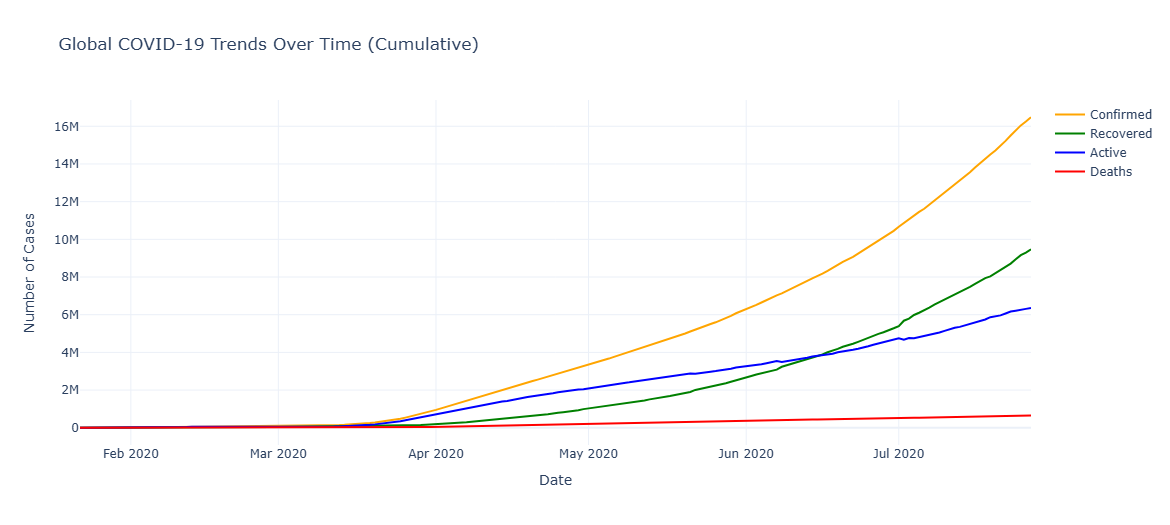

In [18]:
from IPython.display import Image, display

display(Image(filename='images/global_cumulative_trends.png'))

 # 🧠 **Insights:**



🔶 **1. Confirmed Cases Growing Exponentially
The orange line is steeply rising, especially from April onward.**

* It indicates a worsening global spread with no clear sign of flattening by July 2020.

* This supports the daily chart you shared earlier: confirmed cases were surging past mid-2020.

🟩 **2. Recovered Cases Growing Steadily but Lagging**

* The green line (Recovered) is consistently below confirmed.

* The gap between confirmed and recovered widens over time, showing:

 *  Recoveries are increasing

 *  But not fast enough to close the gap caused by daily new cases

🔵 **3. Active Cases Remain High**

* The blue line (Active cases = Confirmed - Recovered - Deaths) is climbing continuously until July.

* This means many people were still infected and not yet recovered.

* The slope doesn’t flatten — so pressure on healthcare systems was likely ongoing.

🔴 **4. Deaths Are Rising, but Slowly Compared to Other Lines**

* The red line has the shallowest slope.

* This suggests:

 *  The fatality rate is relatively low (compared to total infections)

 *  But the number is still growing slowly and steadily — not yet flattened

📏 **5. Spacing Between Lines Gives Extra Clues**

* The widening gap between confirmed and recovered = ongoing high infection rate

* The relatively small gap between active and confirmed means a large portion of cases were still unresolved

**🧾 Summary of Insights (For Using in Report):**

1. Confirmed cases grew exponentially through July 2020, showing the virus was far from under control.

2. Recovery rates increased steadily, but not fast enough to catch up with new infections.

3. Active cases were climbing, suggesting sustained stress on healthcare systems.

4. Deaths rose slowly in comparison, indicating a relatively low fatality rate, but still a serious public health impact.

5. The widening gap between confirmed and recovered cases highlights the need for better containment and treatment strategies.

**2. india**

In [19]:
# Plot interactive graph
fig = go.Figure()

fig.add_trace(go.Scatter(x=india_df['Date'], y=india_df['Confirmed'],
                         mode='lines', name='Confirmed', line=dict(color='orange')))
fig.add_trace(go.Scatter(x=india_df['Date'], y=india_df['Recovered'],
                         mode='lines', name='Recovered', line=dict(color='green')))
fig.add_trace(go.Scatter(x=india_df['Date'], y=india_df['Active'],
                         mode='lines', name='Active', line=dict(color='blue')))
fig.add_trace(go.Scatter(x=india_df['Date'], y=india_df['Deaths'],
                         mode='lines', name='Deaths', line=dict(color='red')))

fig.update_layout(title='India COVID-19 Trends Over Time (Cumulative)',
                  xaxis_title='Date',
                  yaxis_title='Number of Cases',
                  hovermode='x unified',
                  template='plotly_white')

fig.show()

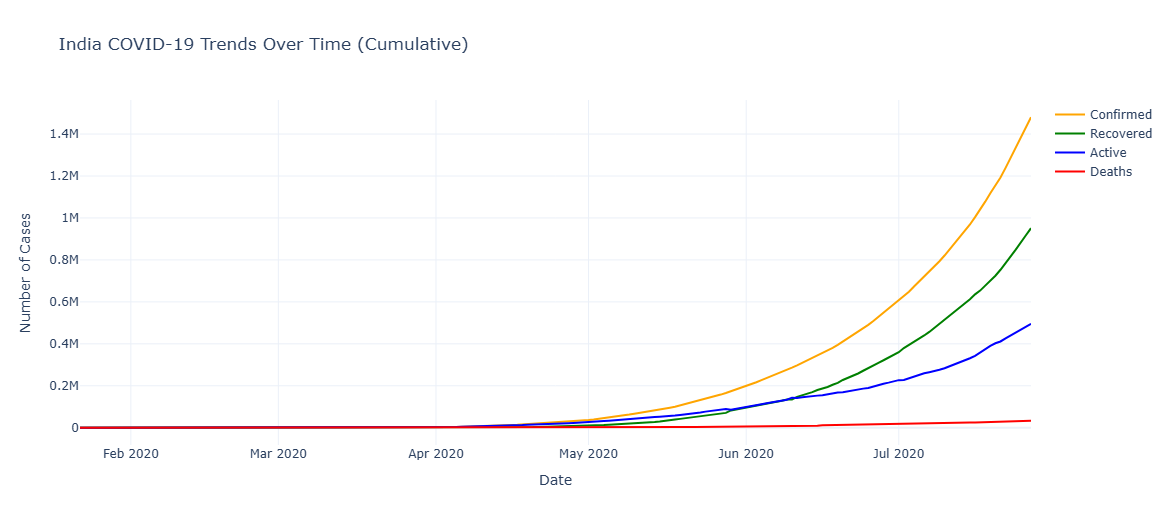

In [20]:
from IPython.display import Image, display

display(Image(filename='images/india_cumulative_trends.png'))

 # ✍ **Analyze Infection & Recovery Rates(Daily impact)**

**Calculate Daily New Cases and Rates**

**1. global**

In [21]:
# Daily values
global_df['New_Confirmed'] = global_df['Confirmed'].diff().fillna(0)
global_df['New_Recovered'] = global_df['Recovered'].diff().fillna(0)

# Infection and Recovery rates
# Infection Rate = new confirmed / total confirmed
global_df['Infection_Rate'] = global_df['New_Confirmed'] / global_df['Confirmed'].replace(0, pd.NA)
# Recovery Rate = new recovered / total recovered
global_df['Recovery_Rate'] = global_df['New_Recovered'] / global_df['Recovered'].replace(0, pd.NA)

# Optional: Smooth rates
global_df['Infection_Rate_Smoothed'] = global_df['Infection_Rate'].rolling(7).mean()
global_df['Recovery_Rate_Smoothed'] = global_df['Recovery_Rate'].rolling(7).mean()


**2. India**

In [22]:
# Daily values
india_df['New_Confirmed'] = india_df['Confirmed'].diff().fillna(0)
india_df['New_Recovered'] = india_df['Recovered'].diff().fillna(0)

# Create the rate columns
india_df['Infection_Rate'] = india_df['New_Confirmed'] / india_df['Confirmed'].replace(0, pd.NA)
india_df['Recovery_Rate'] = india_df['New_Recovered'] / india_df['Recovered'].replace(0, pd.NA)

# Ensure they’re numeric (optional but safe)
india_df['Infection_Rate'] = pd.to_numeric(india_df['Infection_Rate'], errors='coerce')
india_df['Recovery_Rate'] = pd.to_numeric(india_df['Recovery_Rate'], errors='coerce')

# Now you can smooth it
india_df['Infection_Rate_Smoothed'] = india_df['Infection_Rate'].rolling(7).mean()
india_df['Recovery_Rate_Smoothed'] = india_df['Recovery_Rate'].rolling(7).mean()


**📉 Plot Infection and Recovery Trends(Showing Trends & Waves)**

📊 **Daily New Confirmed cases over time**

**1. global**

**✅ What This Graph Represents:**

* It tracks the number of new COVID-19 cases reported each day globally.

* Based on .diff() from the cumulative Confirmed column.

* It helps visualize how fast and aggressively the virus is spreading day by day.

In [23]:
# New Confirmed over time
fig1 = px.line(global_df, x='Date', y='New_Confirmed', title='Daily New Confirmed Cases')
fig1.show()

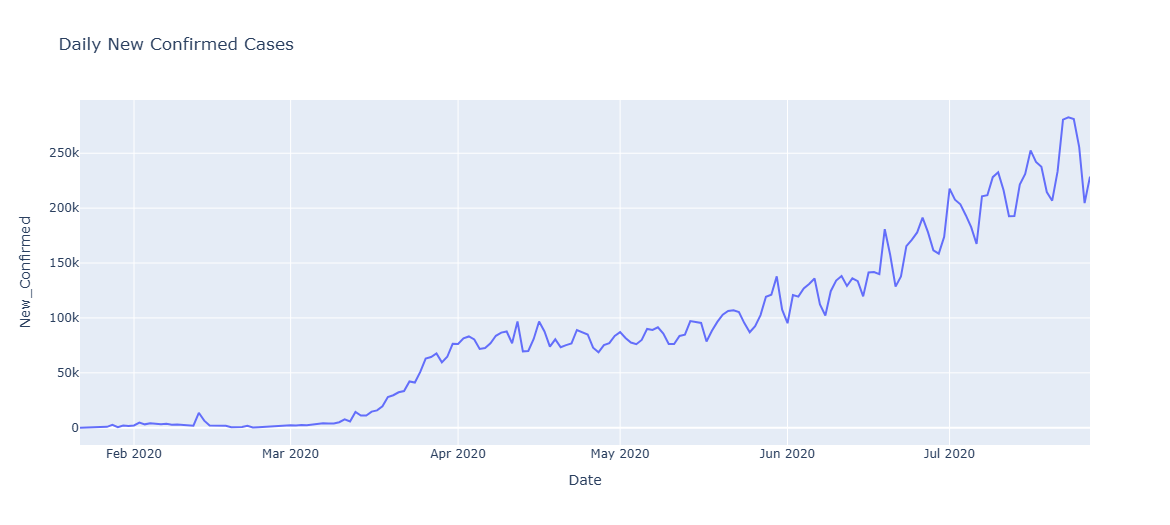

In [24]:
from IPython.display import Image, display

display(Image(filename='images/global_daily_cases.png'))

 # **🧠 Key Insights from the Chart:**

📈 **1. Exponential Growth After March 2020**
* In February to mid-March, daily new cases were relatively low (under 10,000).

* Around late March to April, the curve starts rising sharply, indicating a rapid global spread.

📉 **2. Wave-Like Pattern Visible**

* From April to July, the graph shows weekly fluctuations.

* These up-and-downs could be due to:

 * Reporting delays on weekends

 * Variation in testing rates

 * Short-term lockdown effects

🔼 **3. Steady Increase into July 2020**

* The graph shows a strong upward trend, reaching over 250,000 daily new cases by end of July.

* This means:

 * Global transmission was far from under control

 * Healthcare systems likely overwhelmed in many regions

🔍 **4. No Sign of Plateauing**

* A plateau (flat region) in this type of chart would indicate stabilization.

* But your chart shows no flattening, meaning case numbers were accelerating.

* This suggests that interventions at that time were not sufficient globally.

⚠️ **5. Spike Peaks Getting Taller**

* Not only are the average daily cases increasing, but the peaks are becoming sharper.

* Could be a sign of:

 * Localized outbreaks

 * Delayed case reporting all showing at once

 * Faster community transmission

**🧾 Final Summary for This Chart (For Using in Report):**

“The daily new confirmed COVID-19 cases showed exponential growth globally from March to July 2020. Despite minor weekly fluctuations, the overall trend remained upward, with daily cases surpassing 250,000 by the end of July. This indicates widespread, uncontrolled transmission. The absence of a plateau and rising peaks reflect either increased testing, reporting lags, or accelerating outbreaks in multiple regions.”

📊 **2. India**

In [25]:
fig1 = px.line(india_df, x='Date', y='New_Confirmed', title='India: Daily New Confirmed Cases')
fig1.show()

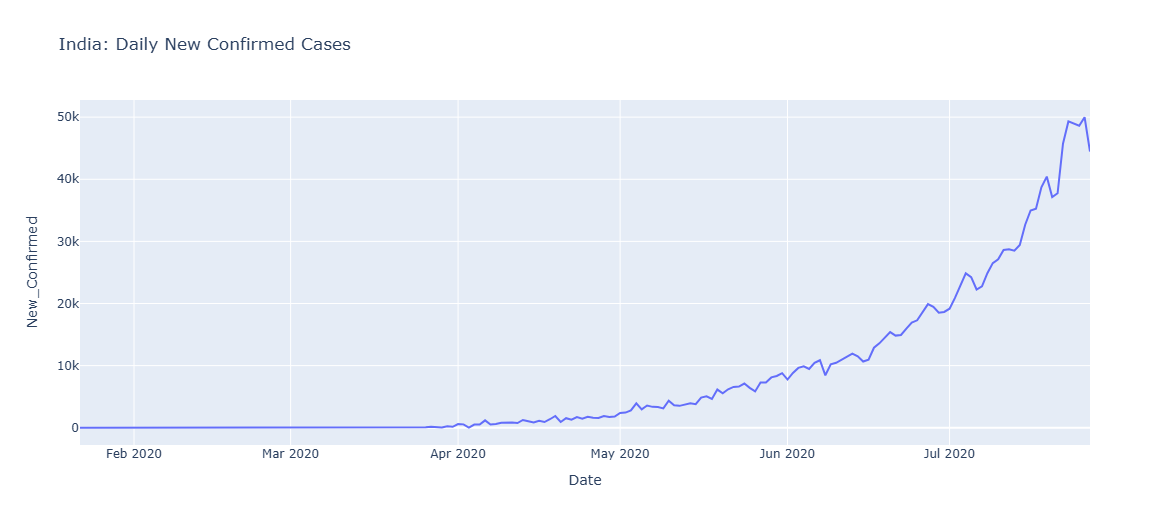

In [26]:
from IPython.display import Image, display

display(Image(filename='images/india_daily_cases.png'))

 🔰**Infection and recovery Rate trend over time**

**1. global**

**✅ What It Shows:**

* Blue line = Infection_Rate_Smoothed

* Red line = Recovery_Rate_Smoothed

* Both values are calculated as:

 * Infection Rate = New Confirmed / Total Confirmed

 * Recovery Rate = New Recovered / Total Recovered

* Smoothed with a 7-day rolling average to reduce noise.

In [27]:
# Infection and recovery Rate trend
px.line(global_df, x='Date', y=['Infection_Rate_Smoothed', 'Recovery_Rate_Smoothed'],
        title='Infection and Recovery Rates Over Time(Global)')

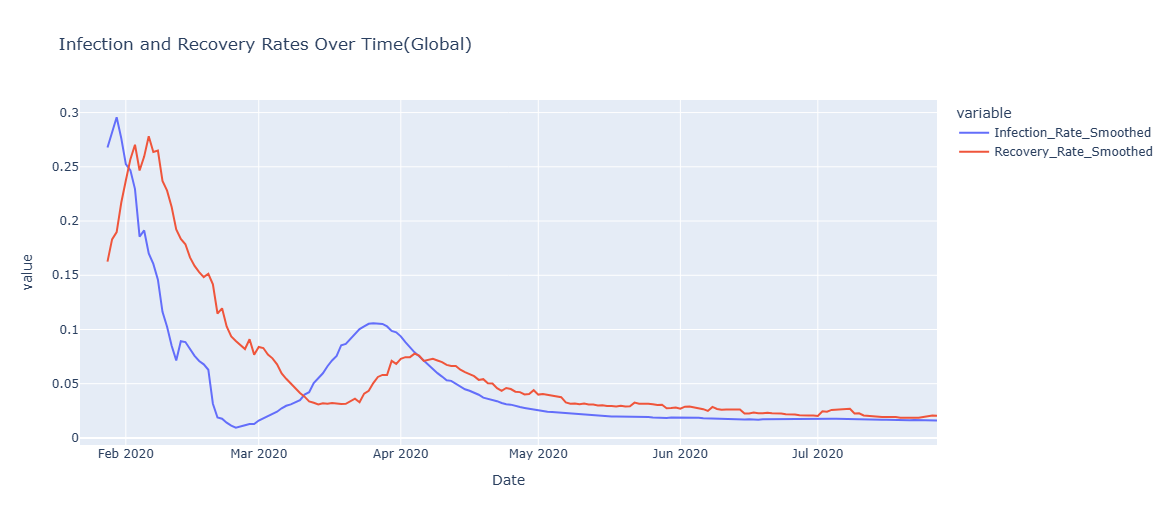

In [28]:
from IPython.display import Image, display

display(Image(filename='images/global_infection_recovery_rates.png'))

 # **🧠 Key Insights from the Graph:**

**🔹 1. Early Spike in Infection Rate (Jan–Feb 2020)**

* Infection rate peaked above 0.3 (~30%) early in the outbreak.

* Reason:

 * Low base of total confirmed cases → even small increases result in high rates.

 * Also reflects rapid early transmission, likely before strict interventions.

**🔴 2. Recovery Rate Catches Up and Surpasses Infection Rate (Feb–March)**

* Recovery rate rises and overtakes infection rate in late February to early March.

* This is a positive public health indicator: more people recovering daily than getting newly infected.

**📉 3. Both Rates Decline and Stabilize (April–July)**

* From April onwards, both rates gradually decrease and then flatten.

* Indicates:

 * Total confirmed and recovered numbers became very large, so daily changes have less impact proportionally.

 * Possibly, recoveries were taking longer, or new cases were rising fast but hidden behind a large base.

**🌀 4. Temporary Rise in Infection Rate (Late March–April)**

* Around April, there’s a slight bump in infection rate again.

* May be due to:

 * Second wave of outbreaks

 * Expanded testing capturing more cases

 * Changes in reporting

**⚠️ 5. Recovery Rate Remains Slightly Higher in Most of the Middle Period**

* Throughout March to May, the red line (recovery rate) stays slightly above infection rate — but both trend downward.

* This implies the outbreak was still expanding, but recoveries were trying to keep pace.

**📌 Final Summary (For Using in Report):**

“At the beginning of the pandemic, infection rates peaked sharply, reaching over 30%, but declined rapidly by March 2020. Recovery rates began to catch up and eventually surpassed infection rates by early March. From April to July, both rates flattened at low values, indicating slower proportional changes due to a high base. However, infection rate fluctuations in April suggest temporary surges or reporting changes. Overall, this trend shows that although the pandemic was spreading rapidly, recovery was improving early on and somewhat stabilized over time.”

 **2. India**

In [29]:
# Infection and recovery Rate trend
px.line(india_df, x='Date', y=['Infection_Rate_Smoothed', 'Recovery_Rate_Smoothed'],
        title='Infection and Recovery Rates Over Time(India)')

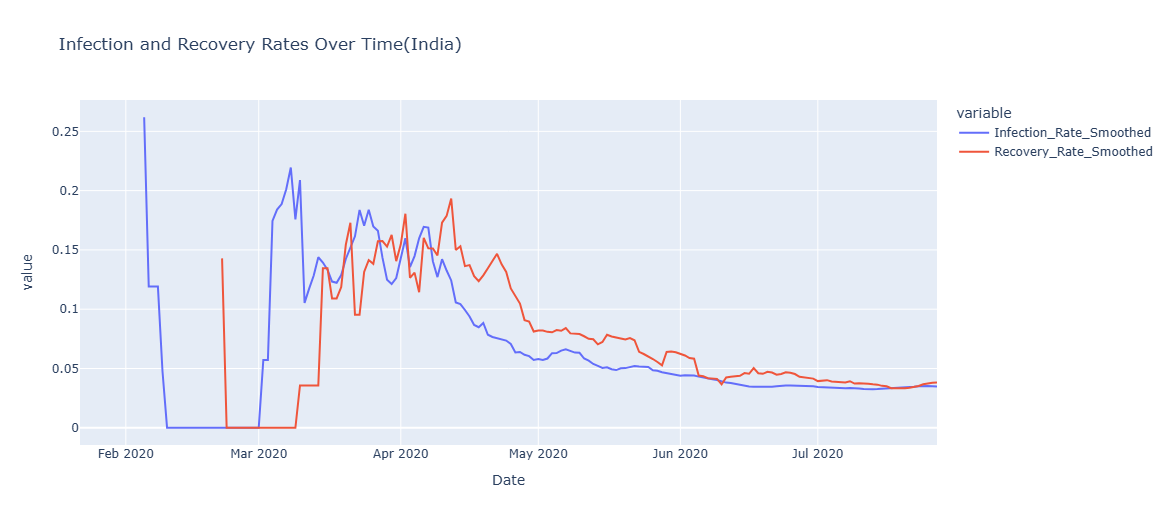

In [30]:
from IPython.display import Image, display

display(Image(filename='images/india_infection_recovery_rates.png'))

# **Step 4 - Forecast Future Cases with Prophet(using total values)**

**Preparing data for Prophet**

**1. global**

In [31]:
prophet_df = global_df[['Date', 'Confirmed']].rename(columns={'Date': 'ds', 'Confirmed': 'y'})

**2. India**

In [32]:
india_prophet = india_df[['Date', 'Confirmed']].rename(columns={'Date': 'ds', 'Confirmed': 'y'})


**Initializing and fiting model**

**1. global**

In [33]:
model = Prophet()
model.fit(prophet_df)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


**2. india**

In [34]:
model_india = Prophet()
model_india.fit(india_prophet)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


**Predicting for 7 Days Ahead**

**1. global**

In [35]:
future = model.make_future_dataframe(periods=7)
forecast = model.predict(future)

**2. india**

In [36]:
future_india = model_india.make_future_dataframe(periods=7)
forecast_india = model_india.predict(future_india)

**Ploting Forecast**

**1- Simple plot**

**1. global**

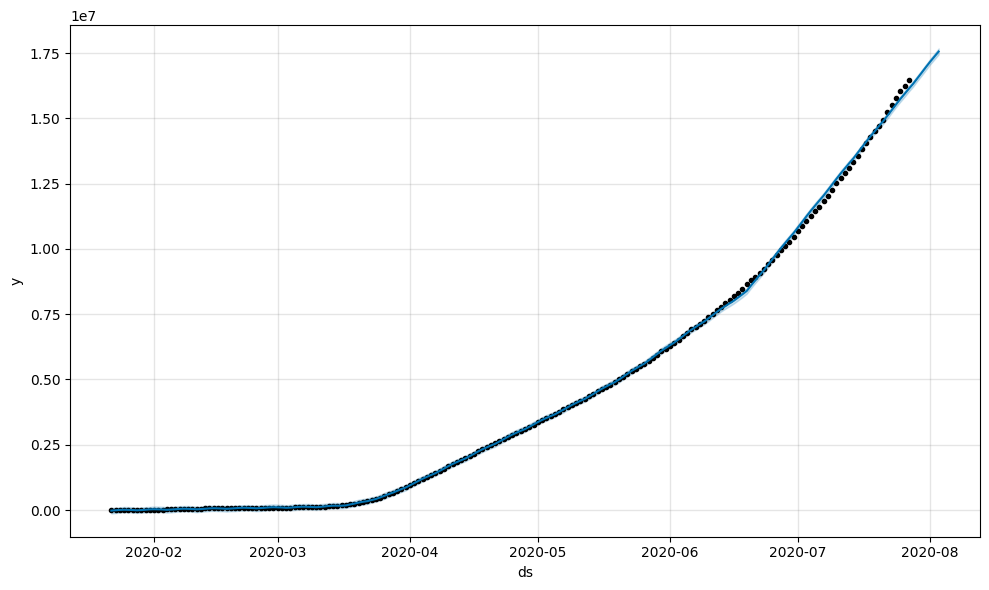

In [37]:
# Plot forecast
fig_forecast = model.plot(forecast)

**2. india**

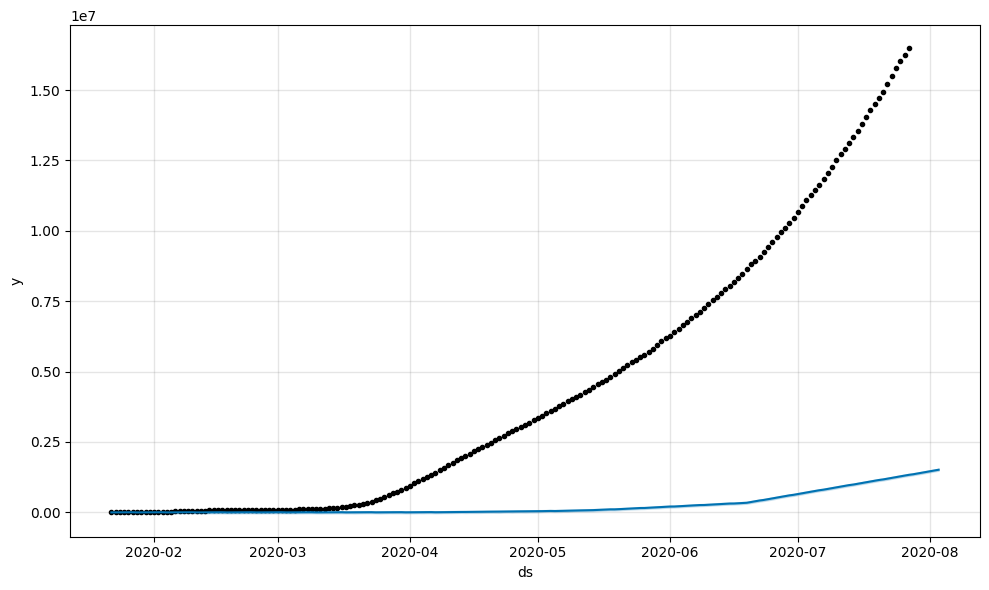

In [38]:
# Plot forecast
fig_forecast_india = model.plot(forecast_india)

**2- Ploting with Plotly**

**1. global**

**✅ What It Shows:**

* Blue line: Actual historical confirmed cases.

* Orange line: Prophet's forecast for confirmed cases (7 days ahead).

* Shaded area (Upper/Lower bounds): Confidence interval showing possible range of values.

In [39]:
# Plot with Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=prophet_df['ds'], y=prophet_df['y'], name='Actual Confirmed', line=dict(color='blue')))
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat'], name='Forecasted', line=dict(color='orange')))
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat_upper'], name='Upper Bound', line=dict(dash='dot', color='lightgrey')))
fig.add_trace(go.Scatter(x=forecast['ds'], y=forecast['yhat_lower'], name='Lower Bound', line=dict(dash='dot', color='lightgrey')))

fig.update_layout(title='COVID-19 Confirmed Cases Forecast (Next 7 Days)',
                  xaxis_title='Date',
                  yaxis_title='Confirmed Cases',
                  hovermode='x unified',
                  template='plotly_white')

fig.show()

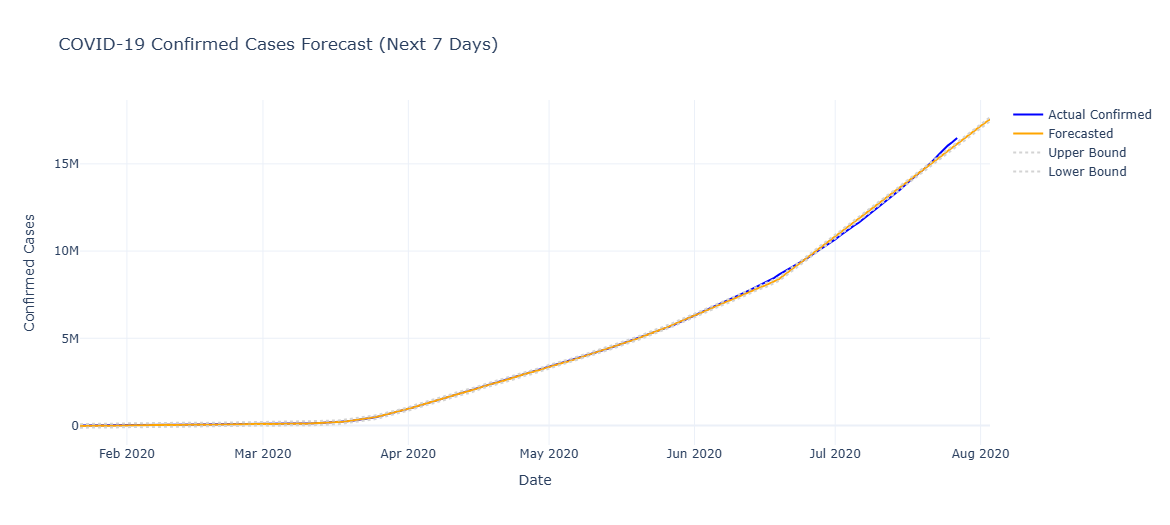

In [40]:
from IPython.display import Image, display

display(Image(filename='images/global_prophet_forecast_plotly.png'))

 # **📈 Key Insights:**

**🔮 1. Forecast Predicts Continued Upward Trend**

* The orange forecast line continues to rise steeply, in line with the historical growth.

* Indicates that if trends continue unchanged, the number of confirmed cases will keep increasing significantly over the next week.

**🔍 2. Model Follows Historical Data Closely**

* The actual data (blue) and forecast (orange) are very closely aligned — good model fit.

* Suggests that Prophet captured the underlying growth pattern accurately, at least in the short term.

**📉 3. Confidence Interval Is Narrow**

* The shaded prediction band (upper/lower bounds) is narrow, showing:

 * High model confidence

 * Little expected volatility over 7 days

* This is typical when:

 * Data has consistent exponential or logistic growth

 * Seasonality and irregularities are minimal

**🗓️ 4. Forecast Window = Short-Term, Reliable**

* Prophet forecasts are generally more reliable in the short term.

* 7-day horizon is a smart and stable choice — balances usefulness with accuracy.



**📌 Final Summary (You Can Use in Your Report):**

“Using the Facebook Prophet model, we forecasted global confirmed COVID-19 cases for the next 7 days. The forecast shows a strong upward trajectory, consistent with past exponential growth. The model closely follows historical data and offers narrow confidence intervals, indicating a stable short-term forecast. If current trends continue, confirmed cases are expected to increase steadily, emphasizing the ongoing nature of the pandemic at this stage.”

**2. india**

In [41]:
import plotly.graph_objects as go

fig4 = go.Figure()

fig4.add_trace(go.Scatter(x=india_prophet['ds'], y=india_prophet['y'],
                          mode='lines', name='Actual Confirmed'))

fig4.add_trace(go.Scatter(x=forecast_india['ds'], y=forecast_india['yhat'],
                          mode='lines', name='Forecasted'))

fig4.add_trace(go.Scatter(x=forecast_india['ds'], y=forecast_india['yhat_upper'],
                          mode='lines', name='Upper Bound', line=dict(dash='dot')))
fig4.add_trace(go.Scatter(x=forecast_india['ds'], y=forecast_india['yhat_lower'],
                          mode='lines', name='Lower Bound', line=dict(dash='dot')))

fig4.update_layout(title='India COVID-19 Confirmed Cases Forecast (Next 7 Days)',
                   xaxis_title='Date',
                   yaxis_title='Confirmed Cases')
fig4.show()


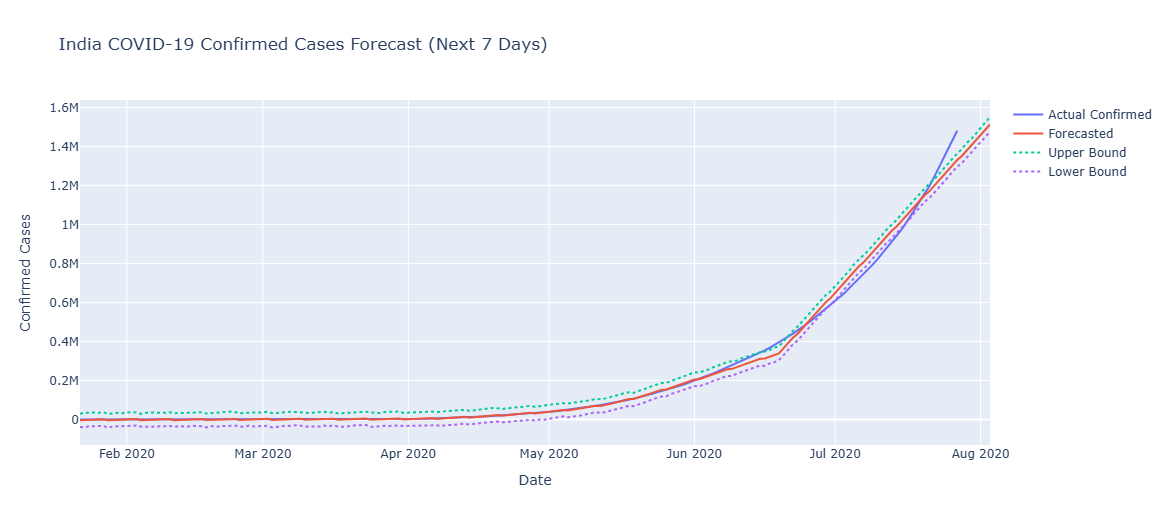

In [42]:
from IPython.display import Image, display

display(Image(filename='images/india_prophet_forecast_plotly.png'))

**Display Future Numbers**

**1. global**

In [43]:
forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(7)

,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.632009e+07,1.621250e+07,1.641996e+07
189,2020-07-29,1.652989e+07,1.643229e+07,1.663411e+07
190,2020-07-30,1.674383e+07,1.663732e+07,1.684410e+07
191,2020-07-31,1.695907e+07,1.685037e+07,1.705820e+07
192,2020-08-01,1.716669e+07,1.706514e+07,1.727263e+07
193,2020-08-02,1.736419e+07,1.725550e+07,1.747671e+07
194,2020-08-03,1.755880e+07,1.744862e+07,1.767873e+07


**2. india**

In [44]:
forecast_india[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(7)

,ds,yhat,yhat_lower,yhat_upper
188,2020-07-28,1.350742e+06,1.316885e+06,1.387721e+06
189,2020-07-29,1.377652e+06,1.343194e+06,1.411782e+06
190,2020-07-30,1.404780e+06,1.368490e+06,1.440359e+06
191,2020-07-31,1.432037e+06,1.397121e+06,1.467630e+06
192,2020-08-01,1.459031e+06,1.423254e+06,1.495154e+06
193,2020-08-02,1.486161e+06,1.452726e+06,1.520592e+06
194,2020-08-03,1.512664e+06,1.478386e+06,1.547773e+06
